In [1]:
# ==============================================================================
# BLOQUE PREVIO: INSTALACIÓN DEL ENTORNO X-13ARIMA
# ==============================================================================
!apt-get update -qq
!apt-get install -y x13as > /dev/null 2>&1
print("✓ Binario X-13ARIMA instalado y listo en el sistema de Colab.")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
✓ Binario X-13ARIMA instalado y listo en el sistema de Colab.


In [2]:
# ==============================================================================
# BLOQUE 0: CARGA Y PREPARACIÓN DE DATOS
# ==============================================================================
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.x13 import x13_arima_analysis  # Importación de X-13

warnings.filterwarnings('ignore')

# ------------------------------------------------------------------------------
# CARGA DIRECTA DE DATOS DESDE GITHUB (Garantiza ejecutabilidad universal)
# ------------------------------------------------------------------------------
URL_EXCEL = "https://raw.githubusercontent.com/gabrielapebb/Econometr-a-2/main/anex-IPI-ago2026.xlsx"

# Carga de la base de datos
df = pd.read_excel(URL_EXCEL)

# Carga de datos
df_raw = pd.read_excel(URL_EXCEL, sheet_name=3, skiprows=7)
if 'División/Clase' not in df_raw.columns and df_raw.iloc[0].str.contains('División/Clase').any():
    df_raw.columns = df_raw.iloc[0]
    df_raw = df_raw[1:].reset_index(drop=True)

df_ipi = df_raw[df_raw['División/Clase'] == 'T_IPI'].copy()
df_ipi['Fecha'] = pd.date_range(start='2014-01-01', periods=len(df_ipi), freq='MS')
df_ipi.set_index('Fecha', inplace=True)
serie_ipi = df_ipi['Producción real'].astype(float)

print(f"✓ Datos cargados correctamente: {len(serie_ipi)} observaciones.")


✓ Datos cargados correctamente: 152 observaciones.


✓ Serie desestacionalizada con éxito usando X-13ARIMA-SEATS.


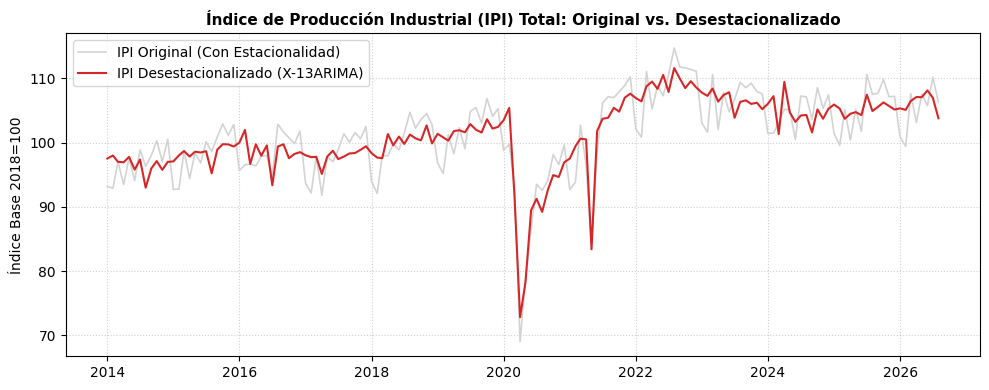

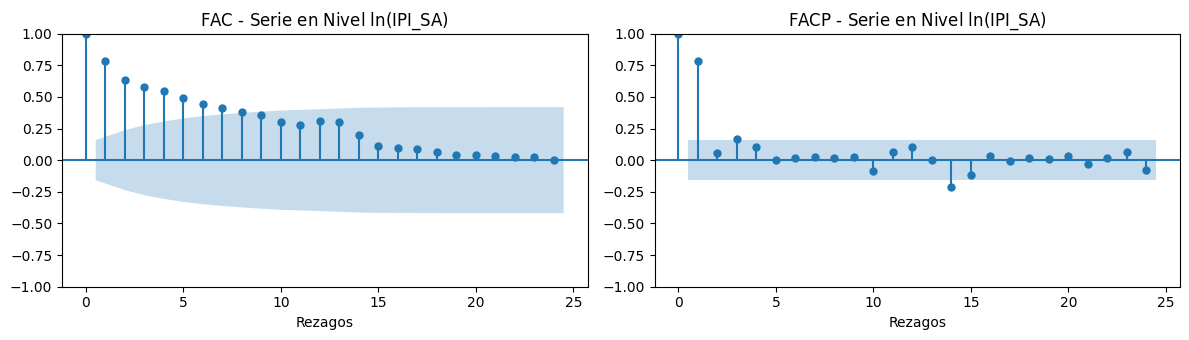

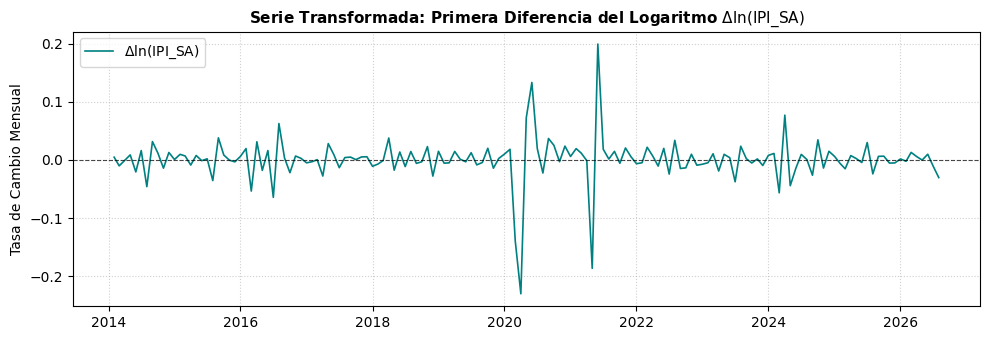

 PRUEBA DICKEY-FULLER AUMENTADA EN Δln(IPI_SA)
Estadístico ADF: -9.8812
p-valor: 3.7662e-17
Conclusión: La serie desestacionalizada en primera diferencia es ESTACIONARIA (d=1)


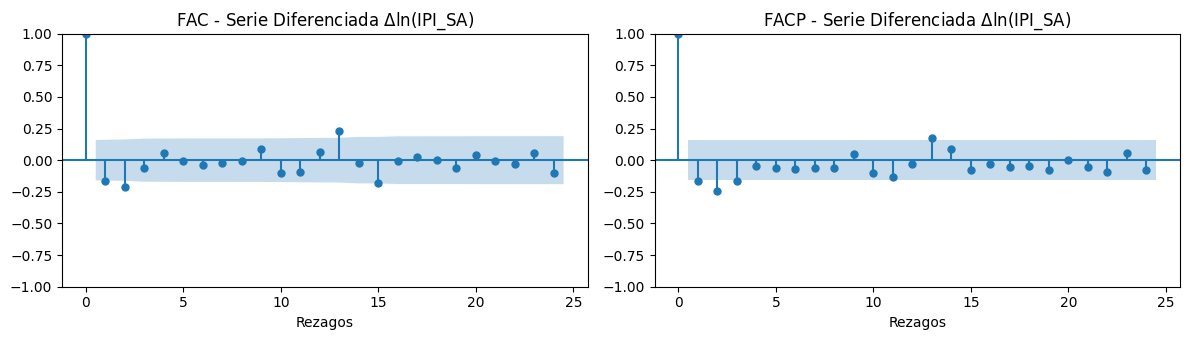

In [3]:
# ==============================================================================
# BLOQUE 1: DESESTACIONALIZACIÓN, ESTACIONARIEDAD Y CORRELOGRAMAS (COMPLETO)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.x13 import x13_arima_analysis

# ------------------------------------------------------------------------------
# 0. DESESTACIONALIZACIÓN DE LA SERIE USANDO X-13ARIMA
# ------------------------------------------------------------------------------
# Usamos el binario x13as instalado en el sistema de Colab
x13_path = "/usr/bin/"

try:
    # Aplicamos X-13ARIMA sobre la serie original (cargada en el Bloque 0)
    resultado_x13 = x13_arima_analysis(serie_ipi, x12path=x13_path)
    ipi_sa = resultado_x13.seasadj
    print("✓ Serie desestacionalizada con éxito usando X-13ARIMA-SEATS.")
except Exception as e:
    print(f"Error al ejecutar X-13ARIMA: {e}")
    print("Se utilizará una aproximación por descomposición clásica como respaldo.")
    from statsmodels.tsa.seasonal import seasonal_decompose
    descomposicion = seasonal_decompose(serie_ipi, model='multiplicative', period=12)
    ipi_sa = serie_ipi / descomposicion.seasonal

# ------------------------------------------------------------------------------
# 1. GRÁFICA 1: Serie Original vs. Desestacionalizada (En Niveles)
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 4))
plt.plot(serie_ipi, label='IPI Original (Con Estacionalidad)', color='lightgray', linewidth=1.2)
plt.plot(ipi_sa, label='IPI Desestacionalizado (X-13ARIMA)', color='tab:red', linewidth=1.5)

plt.title('Índice de Producción Industrial (IPI) Total: Original vs. Desestacionalizado', fontsize=11, fontweight='bold')
plt.ylabel('Índice Base 2018=100')
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 2. TRANSFORMACIÓN LOGARÍTMICA DE LA SERIE DESESTACIONALIZADA
# ------------------------------------------------------------------------------
y_log_sa = np.log(ipi_sa)

# ------------------------------------------------------------------------------
# 3. GRÁFICA 2: Correlogramas FAC y FACP de la Serie en NIVEL ln(IPI_SA)
# (Demuestra la alta autocorrelación y justifica la necesidad de la diferencia d=1)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

plot_acf(y_log_sa, ax=axes[0], lags=24, title=r'FAC - Serie en Nivel $\ln(\mathrm{IPI\_SA})$')
axes[0].set_xlabel('Rezagos')

plot_pacf(y_log_sa, ax=axes[1], lags=24, title=r'FACP - Serie en Nivel $\ln(\mathrm{IPI\_SA})$')
axes[1].set_xlabel('Rezagos')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 4. PRIMERA DIFERENCIA: dy_log_sa = Δln(IPI_SA)
# ------------------------------------------------------------------------------
dy_log_sa = y_log_sa.diff().dropna()

# ------------------------------------------------------------------------------
# 5. GRÁFICA 3: Serie Desestacionalizada en Primera Diferencia
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 3.5))
plt.plot(dy_log_sa, color='teal', linewidth=1.2, label=r'$\Delta \ln(\mathrm{IPI\_SA})$')
plt.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.title(r'Serie Transformada: Primera Diferencia del Logaritmo $\Delta \ln(\mathrm{IPI\_SA})$', fontsize=11, fontweight='bold')
plt.ylabel('Tasa de Cambio Mensual')
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 6. PRUEBA DICKEY-FULLER AUMENTADA (ADF) SOBRE LA SERIE DIFERENCIADA
# ------------------------------------------------------------------------------
adf_test = adfuller(dy_log_sa)
print("="*75)
print(" PRUEBA DICKEY-FULLER AUMENTADA EN Δln(IPI_SA)")
print("="*75)
print(f"Estadístico ADF: {adf_test[0]:.4f}")
print(f"p-valor: {adf_test[1]:.4e}")
if adf_test[1] < 0.05:
    print("Conclusión: La serie desestacionalizada en primera diferencia es ESTACIONARIA (d=1)")
else:
    print("Conclusión: La serie NO es estacionaria")
print("="*75)

# ------------------------------------------------------------------------------
# 7. GRÁFICA 4: Correlogramas FAC y FACP de la Serie DIFERENCIADA Δln(IPI_SA)
# (Permite la identificación de los órdenes p y q para Box-Jenkins)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

plot_acf(dy_log_sa, ax=axes[0], lags=24, title=r'FAC - Serie Diferenciada $\Delta \ln(\mathrm{IPI\_SA})$')
axes[0].set_xlabel('Rezagos')

plot_pacf(dy_log_sa, ax=axes[1], lags=24, title=r'FACP - Serie Diferenciada $\Delta \ln(\mathrm{IPI\_SA})$')
axes[1].set_xlabel('Rezagos')

plt.tight_layout()
plt.show()

In [4]:
# ==============================================================================
# BLOQUE 2: ESTIMACIÓN COMPARATIVA DE MODELOS CANDIDATOS CON ERRORES ESTÁNDAR
# ==============================================================================
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Diccionario con las especificaciones candidatas
especificaciones = {
    'ARIMA(1,1,0)': (1, 1, 0),
    'ARIMA(2,1,0)': (2, 1, 0),
    'ARIMA(3,1,0)': (3, 1, 0)
}

resultados_modelos = {}
filas_cuadro = ['Constante (c)', 'AR(1)', 'AR(2)', 'AR(3)', 'Observaciones', 'AIC', 'BIC']

# Dataframe para almacenar el cuadro comparativo
cuadro_comparativo = pd.DataFrame(index=filas_cuadro)

for nombre, order in especificaciones.items():
    # Estimación del modelo sobre log(IPI_SA) con d=1
    mod = SARIMAX(
        np.log(ipi_sa),
        order=order,
        trend='c',
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    res = mod.fit(disp=False)
    resultados_modelos[nombre] = res

    # Extracción de parámetros y errores estándar (.bse)
    params = res.params
    bse = res.bse
    pvals = res.pvalues

    # Función para asignar estrellas de significancia
    def get_stars(p):
        if p < 0.01: return '***'
        elif p < 0.05: return '**'
        elif p < 0.10: return '*'
        return ''

    # Formatear Coeficiente (Error Estándar)
    def format_param(key):
        if key in params:
            val = params[key]
            se = bse[key]
            stars = get_stars(pvals[key])
            return f"{val:.4f}{stars} ({se:.4f})"
        return "-"

    # Guardar en la columna del modelo actual
    cuadro_comparativo[nombre] = [
        format_param('intercept'),
        format_param('ar.L1'),
        format_param('ar.L2'),
        format_param('ar.L3'),
        len(ipi_sa),
        round(res.aic, 2),
        round(res.bic, 2)
    ]

# Definir el modelo ARIMA(2,1,0) como principal para su posterior diagnóstico de residuales
modelo_principal = resultados_modelos['ARIMA(2,1,0)']

print("="*75)
print(" CUADRO COMPARATIVO DE MODELOS ESTIMADOS (CON ERRORES ESTÁNDAR)")
print("="*75)
print(cuadro_comparativo)
print("="*75)
print("Nota: Coeficientes reportados como Coeficiente*** (Error Estándar).")
print("Significancia: * p<0.10, ** p<0.05, *** p<0.01.")

 CUADRO COMPARATIVO DE MODELOS ESTIMADOS (CON ERRORES ESTÁNDAR)
                      ARIMA(1,1,0)         ARIMA(2,1,0)         ARIMA(3,1,0)
Constante (c)      0.0005 (0.0039)      0.0007 (0.0042)      0.0009 (0.0044)
AR(1)          -0.1673*** (0.0342)  -0.2086*** (0.0360)  -0.2486*** (0.0378)
AR(2)                            -  -0.2460*** (0.0586)  -0.2801*** (0.0822)
AR(3)                            -                    -   -0.1628** (0.0749)
Observaciones                  152                  152                  152
AIC                        -546.46               -549.1              -546.32
BIC                        -537.43              -537.08              -531.34
Nota: Coeficientes reportados como Coeficiente*** (Error Estándar).
Significancia: * p<0.10, ** p<0.05, *** p<0.01.



 PRUEBA DE BREUSCH-GODFREY (AUTOCORRELACIÓN SERIAL LM)
              Estadístico LM  p-valor         Conclusión (α = 0.05)
Rezago (Lag)                                                       
4                     3.2276   0.5205  Cumple (Sin Autocorrelación)
8                     3.2812   0.9155  Cumple (Sin Autocorrelación)
12                    3.3100   0.9929  Cumple (Sin Autocorrelación)
16                    3.3415   0.9997  Cumple (Sin Autocorrelación)
24                    3.4282   1.0000  Cumple (Sin Autocorrelación)
 1. PRUEBA DE LJUNG-BOX (NO AUTOCORRELACIÓN SERIAL)
              Estadístico Ljung-Box  p-valor  Conclusión (α = 0.05)
Rezago (Lag)                                                       
4                            4.8523   0.3028  Cumple (Ruido Blanco)
8                            5.3575   0.7188  Cumple (Ruido Blanco)
12                           9.1696   0.6884  Cumple (Ruido Blanco)
16                          21.6513   0.1548  Cumple (Ruido Blanco)
24      

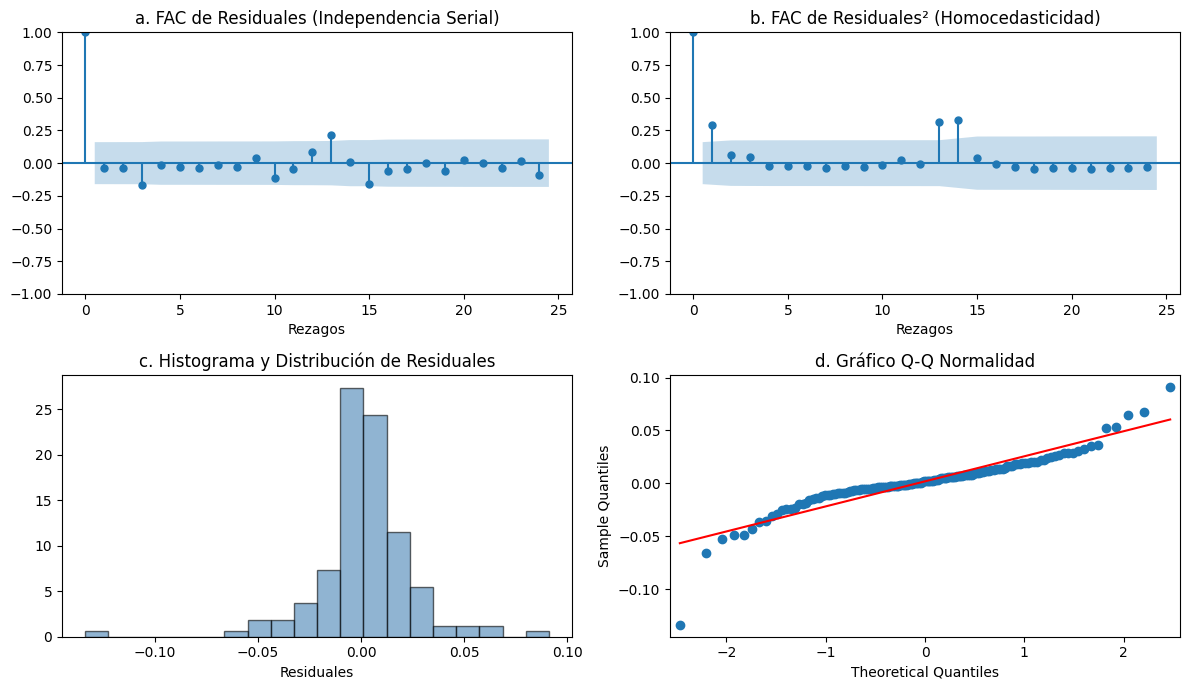

In [5]:
# ==============================================================================
# BLOQUE 3: PRUEBAS FORMALES Y DIAGNÓSTICO GRÁFICO DE RESIDUALES
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera

# 1. Extraer los residuales del modelo seleccionado (ARIMA 2,1,0 o 3,1,0)
# Se descartan los primeros periodos de ajuste de la diferenciación
residuos = modelo_principal.resid.iloc[3:].dropna()
rezagos_evaluar = [4, 8, 12, 16, 24]

# ------------------------------------------------------------------------------
# A. PRUEBAS FORMALES DE HIPÓTESIS SOBRE LOS RESIDUALES
# ------------------------------------------------------------------------------

# 1. Prueba de Ljung-Box (No Autocorrelación Serial / Ruido Blanco)
lb_df = acorr_ljungbox(residuos, lags=rezagos_evaluar, return_df=True)
lb_df.index.name = 'Rezago (Lag)'
lb_df.columns = ['Estadístico Ljung-Box', 'p-valor']
lb_df['Conclusión (α = 0.05)'] = lb_df['p-valor'].apply(
    lambda p: 'Cumple (Ruido Blanco)' if p > 0.05 else 'No Cumple'
)

# 2. Prueba ARCH-LM de Engle (Homocedasticidad / Sin Efectos ARCH)
arch_resultados = []
for lag in rezagos_evaluar:
    stat, pval, _, _ = het_arch(residuos, nlags=lag)
    arch_resultados.append({
        'Rezago (Lag)': lag,
        'Estadístico ARCH-LM': round(stat, 4),
        'p-valor': round(pval, 4),
        'Conclusión (α = 0.05)': 'Cumple (Homocedástico)' if pval > 0.05 else 'Efecto ARCH'
    })
arch_df = pd.DataFrame(arch_resultados).set_index('Rezago (Lag)')

# 3. Prueba de Jarque-Bera (Normalidad de Errores)
jb_stat, jb_pval, skew, kurt = jarque_bera(residuos)

from statsmodels.stats.diagnostic import acorr_breusch_godfrey

# 4. Prueba de Breusch-Godfrey (LM Test para Autocorrelación Serial)

bg_resultados = []
for lag in rezagos_evaluar:
    # Retorna: estadístico lm, p-valor lm, estadístico f, p-valor f
    lm_stat, pval, _, _ = acorr_breusch_godfrey(modelo_principal, nlags=lag)
    bg_resultados.append({
        'Rezago (Lag)': lag,
        'Estadístico LM': round(lm_stat, 4),
        'p-valor': round(pval, 4),
        'Conclusión (α = 0.05)': 'Cumple (Sin Autocorrelación)' if pval > 0.05 else 'Autocorrelación'
    })

bg_df = pd.DataFrame(bg_resultados).set_index('Rezago (Lag)')

print("\n" + "="*75)
print(" PRUEBA DE BREUSCH-GODFREY (AUTOCORRELACIÓN SERIAL LM)")
print("="*75)
print(bg_df.to_string())
print("="*75)


# Impresión de Resultados Formateados
print("="*75)
print(" 1. PRUEBA DE LJUNG-BOX (NO AUTOCORRELACIÓN SERIAL)")
print("="*75)
print(lb_df.round(4).to_string())

print("\n" + "="*75)
print(" 2. PRUEBA ARCH-LM (HOMOCEDASTICIDAD RESIDUAL)")
print("="*75)
print(arch_df.to_string())

print("\n" + "="*75)
print(" 3. PRUEBA DE JARQUE-BERA (NORMALIDAD)")
print("="*75)
print(f"Estadístico JB: {jb_stat:.4f} | p-valor: {jb_pval:.4e}")
print(f"Asimetría (Skewness): {skew:.4f} | Curtosis: {kurt:.4f}")
print(f"Conclusión (α = 0.05): {'Cumple (Normal)' if jb_pval > 0.05 else 'Desviación en colas (COVID-19)'}")
print("="*75)

# ------------------------------------------------------------------------------
# B. DIAGNÓSTICO GRÁFICO EN PANEL (2x2) PARA EL PÓSTER
# ------------------------------------------------------------------------------
# Filtrado de escala exclusivamente para la representación del Histograma y Q-Q
residuos_vis = residuos[np.abs(residuos) < 0.15]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

# a) FAC de Residuales (Autocorrelación)
plot_acf(residuos, ax=axes[0, 0], lags=24, title="a. FAC de Residuales (Independencia Serial)")
axes[0, 0].set_xlabel("Rezagos")

# b) FAC de Residuales al Cuadrado (Volatilidad)
plot_acf(residuos**2, ax=axes[0, 1], lags=24, title="b. FAC de Residuales² (Homocedasticidad)")
axes[0, 1].set_xlabel("Rezagos")

# c) Histograma y Distribución de Residuales
axes[1, 0].hist(residuos_vis, bins=20, density=True, alpha=0.6, color='steelblue', edgecolor='black')
axes[1, 0].set_title("c. Histograma y Distribución de Residuales")
axes[1, 0].set_xlabel("Residuales")

# d) Gráfico Q-Q de Normalidad
sm.qqplot(residuos_vis, line='s', ax=axes[1, 1])
axes[1, 1].set_title("d. Gráfico Q-Q Normalidad")

plt.tight_layout()
plt.show()

 TABLA DE PRONÓSTICOS PUNTUALES E INTERVALOS (10 MESES ADELANTE)
            Pronóstico IPI (SA)  Límite Inferior (95%)  Límite Superior (95%)
2026-09-01               104.79                  97.40                 112.74
2026-10-01               105.44                  96.05                 115.74
2026-11-01               105.13                  94.87                 116.50
2026-12-01               105.11                  93.77                 117.83
2027-01-01               105.27                  92.85                 119.35
2027-02-01               105.32                  92.01                 120.56
2027-03-01               105.35                  91.22                 121.67
2027-04-01               105.41                  90.49                 122.79
2027-05-01               105.47                  89.81                 123.86
2027-06-01               105.52                  89.17                 124.87


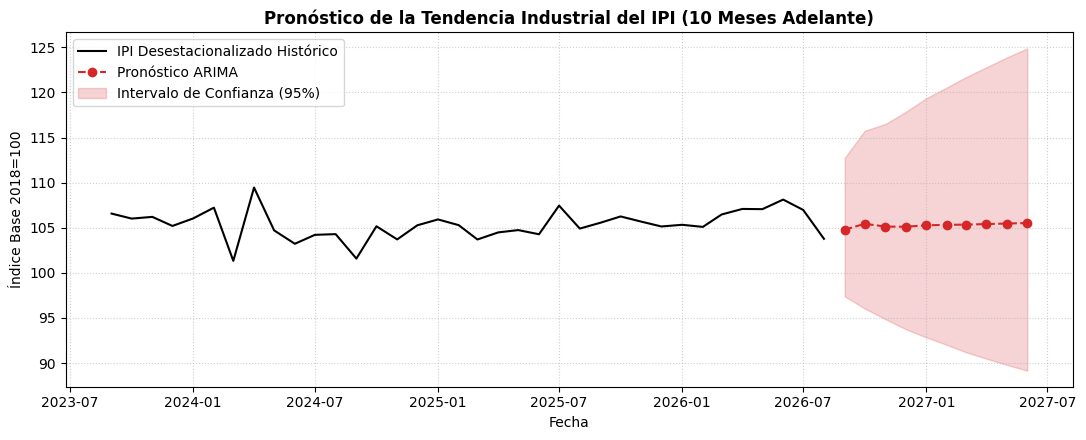

In [6]:
# ==============================================================================
# BLOQUE 4: PRONÓSTICO A 10 PERIODOS Y TABLA DE RESULTADOS (SECCIÓN 4.1 GUÍA)
# ==============================================================================
HORIZONTE = 10

# 1. Generar la proyección a 10 meses con el modelo_principal seleccionado
fc_obj = modelo_principal.get_forecast(steps=HORIZONTE)

# 2. Retransformación exponencial a la escala original del índice IPI desestacionalizado
fc_ipi_sa = np.exp(fc_obj.predicted_mean)
conf_int_sa = np.exp(fc_obj.conf_int(alpha=0.05))

# 3. Construcción del DataFrame con el pronóstico puntual e intervalos al 95%
df_pronostico = pd.DataFrame({
    'Pronóstico IPI (SA)': fc_ipi_sa,
    'Límite Inferior (95%)': conf_int_sa.iloc[:, 0],
    'Límite Superior (95%)': conf_int_sa.iloc[:, 1]
})

print("="*65)
print(f" TABLA DE PRONÓSTICOS PUNTUALES E INTERVALOS (10 MESES ADELANTE)")
print("="*65)
print(df_pronostico.round(2).to_string())

# ------------------------------------------------------------------------------
# 4. GRÁFICA DE PRONÓSTICO EN ALTA RESOLUCIÓN PARA EL PÓSTER
# ------------------------------------------------------------------------------
plt.figure(figsize=(11, 4.5))

# Graficar los últimos 36 meses históricos para apreciar la transición al pronóstico
plt.plot(ipi_sa.tail(36).index, ipi_sa.tail(36), label='IPI Desestacionalizado Histórico', color='black', linewidth=1.5)

# Graficar la trayectoria proyectada
plt.plot(df_pronostico.index, df_pronostico['Pronóstico IPI (SA)'], label='Pronóstico ARIMA', color='tab:red', linestyle='--', marker='o')

# Sombra del intervalo de confianza al 95%
plt.fill_between(
    df_pronostico.index,
    df_pronostico['Límite Inferior (95%)'],
    df_pronostico['Límite Superior (95%)'],
    color='tab:red', alpha=0.2, label='Intervalo de Confianza (95%)'
)

plt.title('Pronóstico de la Tendencia Industrial del IPI (10 Meses Adelante)', fontsize=12, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Índice Base 2018=100')
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Guardar la imagen en alta definición para pegarla en el póster
plt.savefig('pronostico_ipi_poster.png', dpi=300)
plt.show()
